# Multi-Label Classification on Yeast

Build an MLP that predicts multiple biological-function labels per sample, and study how the decision threshold changes evaluation metrics.

Completed as part of my Deep Learning coursework. The notebook combines implementation, experiments, results, and the concepts explored.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PALETTE = ['#2563eb', '#0891b2', '#ea580c', '#7c3aed', '#16a34a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})

def show_architecture(stages, title):
    """Draw a compact network/data-flow diagram with readable layer dimensions."""
    columns = min(4, len(stages))
    rows = (len(stages) + columns - 1) // columns
    fig, ax = plt.subplots(figsize=(12, 2.1 * rows))
    ax.set_xlim(-.2, columns * 3); ax.set_ylim(-.2, rows * 2)
    ax.axis('off')
    centers=[]
    for i, label in enumerate(stages):
        row,col=divmod(i,columns)
        if row % 2: col=columns-1-col
        x=col*3; y=(rows-1-row)*2+.3
        box=FancyBboxPatch((x,y),2.4,1.25,boxstyle='round,pad=0.12',
                           facecolor=PALETTE[i%len(PALETTE)],edgecolor='none',alpha=.94)
        ax.add_patch(box)
        ax.text(x+1.2,y+.625,label,ha='center',va='center',color='white',fontsize=10)
        centers.append((x+1.2,y+.625))
    for (x1,y1),(x2,y2) in zip(centers,centers[1:]):
        if y1==y2:
            direction=1 if x2>x1 else -1
            start=(x1+direction*1.35,y1); end=(x2-direction*1.35,y2)
        else: start=(x1,y1-.75); end=(x2,y2+.75)
        ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.8})
    ax.set_title(title,pad=12)
    plt.tight_layout(); plt.show()

## Model overview

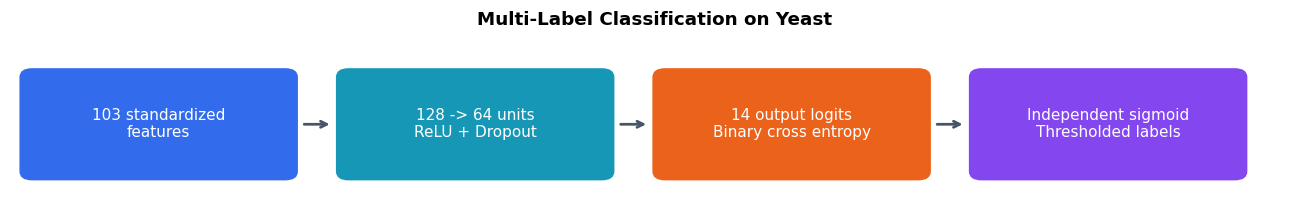

In [2]:
show_architecture(['103 standardized\nfeatures', '128 -> 64 units\nReLU + Dropout', '14 output logits\nBinary cross entropy', 'Independent sigmoid\nThresholded labels'], 'Multi-Label Classification on Yeast')

## Imports and reproducibility

In [3]:
# Multi-Label Classification
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score
from sklearn.impute import SimpleImputer

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)


## Data inspection and label statistics

In [4]:
# Read the attached OpenML multilabel Yeast dataset (version 4).
from pathlib import Path
X = pd.read_csv(next(Path('/kaggle/input').rglob('yeast_features.csv')))
y = pd.read_csv(next(Path('/kaggle/input').rglob('yeast_targets.csv')))
if not isinstance(y, pd.DataFrame) or y.shape[1] < 2:
    raise ValueError("Expected a multi-label target matrix; check the OpenML dataset version.")
print("Missing feature values:", X.isna().sum().sum())
print("Missing target values:", y.isna().sum().sum())
if y.isna().any().any():
    raise ValueError("Missing labels must be resolved explicitly; do not turn them into negatives.")
# Encode semantic label values; category codes can silently reverse positive/negative labels.
label_values = {"0": 0, "0.0": 0, "false": 0, "no": 0,
                "1": 1, "1.0": 1, "true": 1, "yes": 1}
y = y.apply(lambda column: column.astype(str).str.strip().str.lower().map(label_values))
if y.isna().any().any():
    raise ValueError("Unrecognized binary label values; inspect the target categories.")
X_np = X.to_numpy(dtype=float)
y_np = y.to_numpy(dtype=int)
label_cardinality = y_np.sum(axis=1).mean()
label_density = label_cardinality / y_np.shape[1]
print("Feature matrix:", X_np.shape, "Target matrix:", y_np.shape)
print(f"Label cardinality: {label_cardinality:.4f}")
print(f"Label density: {label_density:.4f}")
display(pd.DataFrame({"Label": y.columns, "Positive examples": y_np.sum(axis=0)}))

Missing feature values: 0
Missing target values: 0
Feature matrix: (2417, 103) Target matrix: (2417, 14)
Label cardinality: 4.2371
Label density: 0.3026


,Label,Positive examples
0,Class1,762
1,Class2,1038
2,Class3,983
3,Class4,862
4,Class5,722
5,Class6,597
6,Class7,428
7,Class8,480
8,Class9,178
9,Class10,253


### Label frequency and co-occurrence

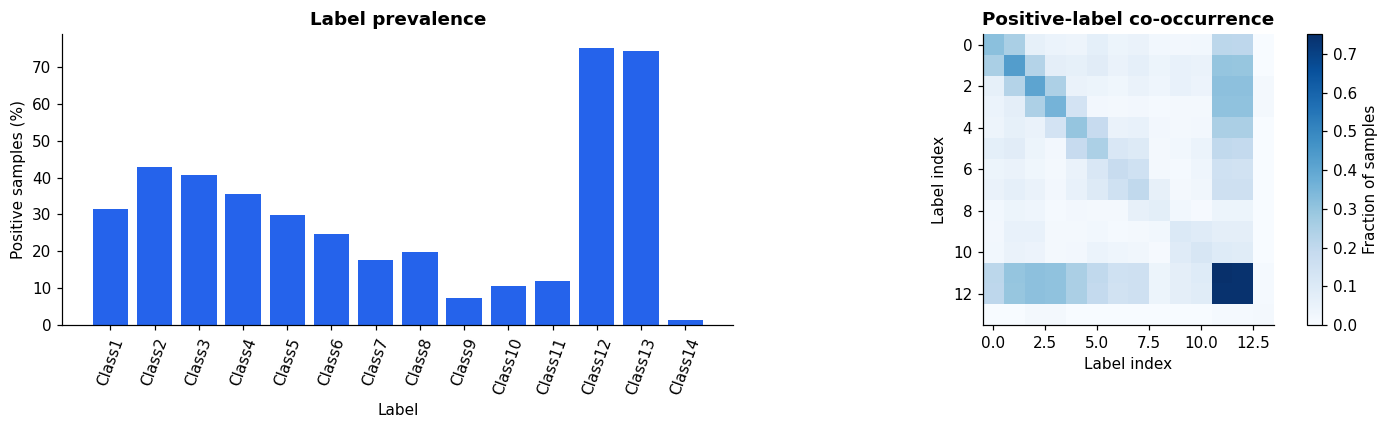

In [5]:
fig, axes=plt.subplots(1,2,figsize=(13,4))
axes[0].bar(y.columns, y_np.mean(axis=0)*100,color=PALETTE[0]); axes[0].tick_params(axis='x',rotation=70)
axes[0].set(xlabel='Label',ylabel='Positive samples (%)',title='Label prevalence')
cooccurrence=y_np.T @ y_np / len(y_np)
im=axes[1].imshow(cooccurrence,cmap='Blues'); fig.colorbar(im,ax=axes[1],label='Fraction of samples')
axes[1].set(xlabel='Label index',ylabel='Label index',title='Positive-label co-occurrence')
plt.tight_layout(); plt.show()

Several labels can be present together. Their different frequencies motivate reporting both micro and macro F1.

### Prevent preprocessing leakage

Split raw samples first, then fit mean imputation and standardization on the training partition only. Apply those same transformations to validation and test data. The seeded random split gives approximately 70%/15%/15%; it is not iterative multi-label stratification, so per-label prevalence can vary between partitions.

## Train/validation/test split

In [6]:
# Task 3a: Split dataset (70% Train, 15% Val, 15% Test)
X_train_val, X_test, y_train_val, y_test = train_test_split(X_np, y_np, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.15/0.85, random_state=42)

print(f"Train size: {X_train.shape[0]}")
print(f"Validation size: {X_val.shape[0]}")
print(f"Test size: {X_test.shape[0]}")

# Fit preprocessing only on the training partition.
imputer = SimpleImputer(strategy="mean")
scaler = StandardScaler()
X_train = scaler.fit_transform(imputer.fit_transform(X_train))
X_val = scaler.transform(imputer.transform(X_val))
X_test = scaler.transform(imputer.transform(X_test))

# Convert to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)


Train size: 1691
Validation size: 363
Test size: 363


## Network architecture

In [7]:
# Task 2: Design MLP Architecture
class MultiLabelMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(MultiLabelMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
            # BCEWithLogitsLoss will be used, so no sigmoid here
        )
        
    def forward(self, x):
        return self.network(x)

input_dim = X_train_t.shape[1]
num_classes = y_train_t.shape[1]
model = MultiLabelMLP(input_dim, num_classes)
print(model)


MultiLabelMLP(
  (network): Sequential(
    (0): Linear(in_features=103, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=14, bias=True)
  )
)


## Training

In [8]:
# Task 3: Model Training
# Select Optimizer and Loss Function
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCEWithLogitsLoss()

# Dataloaders
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

epochs = 100
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(inputs)
        
    train_loss = running_loss / len(train_dataset)
    train_losses.append(train_loss)
    
    # Validation
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t).item()
        val_losses.append(val_loss)
        
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")


Epoch 10/100 | Train Loss: 0.4101 | Val Loss: 0.4291


Epoch 20/100 | Train Loss: 0.3622 | Val Loss: 0.4260


Epoch 30/100 | Train Loss: 0.3269 | Val Loss: 0.4364


Epoch 40/100 | Train Loss: 0.2988 | Val Loss: 0.4494


Epoch 50/100 | Train Loss: 0.2793 | Val Loss: 0.4707


Epoch 60/100 | Train Loss: 0.2609 | Val Loss: 0.4869


Epoch 70/100 | Train Loss: 0.2446 | Val Loss: 0.5028


Epoch 80/100 | Train Loss: 0.2377 | Val Loss: 0.5143


Epoch 90/100 | Train Loss: 0.2250 | Val Loss: 0.5356


Epoch 100/100 | Train Loss: 0.2154 | Val Loss: 0.5489


### Training and validation curves

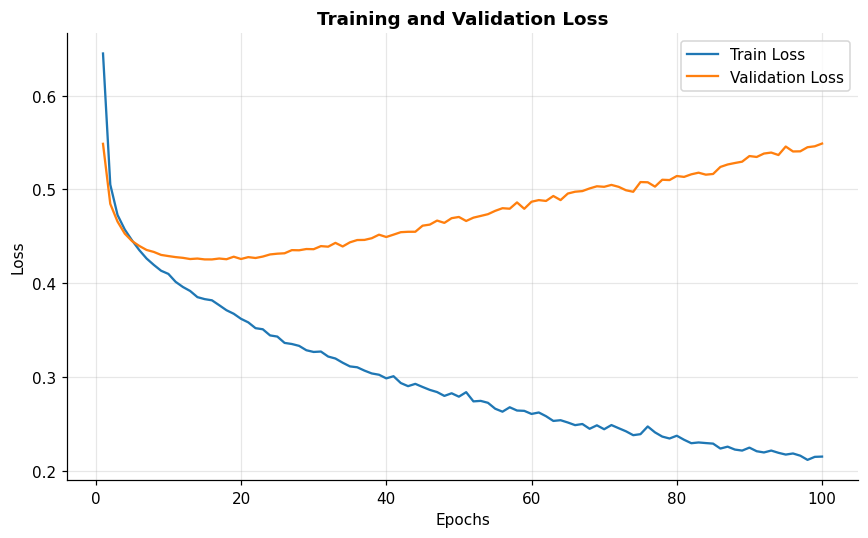

In [9]:
# Plot Training Loss vs Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Test metrics at threshold 0.5

In [10]:
# Task 4: Evaluation and post processing
def evaluate(y_true, y_pred):
    # Hamming Loss
    hamming_loss = np.sum(np.logical_xor(y_true, y_pred)) / (y_true.shape[0] * y_true.shape[1])
    
    # Subset Accuracy (Exact Match Ratio)
    subset_accuracy = accuracy_score(y_true, y_pred)
    
    # Micro and Macro F1
    micro_f1 = f1_score(y_true, y_pred, average='micro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    
    return hamming_loss, subset_accuracy, micro_f1, macro_f1

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.sigmoid(test_logits).numpy()

# Apply threshold of 0.5
threshold = 0.5
test_preds = (test_probs >= threshold).astype(int)

hl, sa, micro_f1, macro_f1 = evaluate(y_test, test_preds)
print(f"Results with Threshold {threshold}:")
print(f"Hamming Loss: {hl:.4f}")
print(f"Subset Accuracy: {sa:.4f}")
print(f"Micro F1-Score: {micro_f1:.4f}")
print(f"Macro F1-Score: {macro_f1:.4f}")


Results with Threshold 0.5:
Hamming Loss: 0.2090
Subset Accuracy: 0.1928
Micro F1-Score: 0.6434
Macro F1-Score: 0.4371


## Validation threshold search

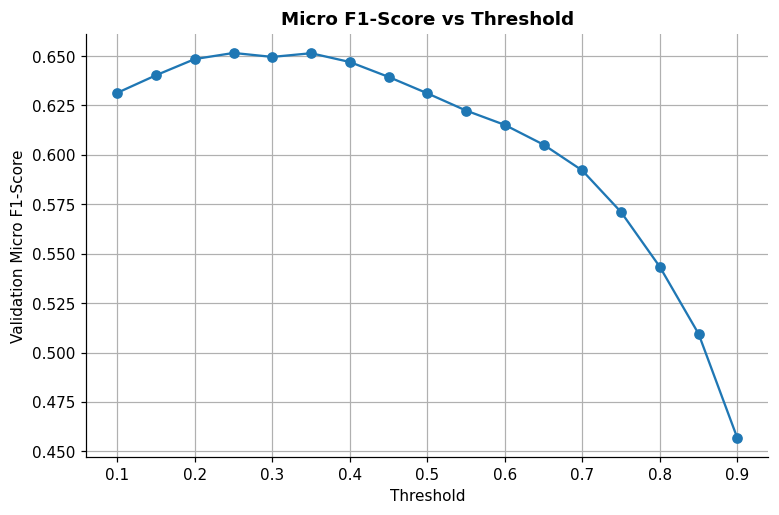

Optimal Threshold based on Validation Micro F1: 0.25


In [11]:
# Task 5: Tune the threshold value
thresholds = np.round(np.arange(0.1, 0.9001, 0.05), 2)
val_micro_f1s = []

model.eval()
with torch.no_grad():
    val_logits = model(X_val_t)
    val_probs = torch.sigmoid(val_logits).numpy()

for th in thresholds:
    val_preds = (val_probs >= th).astype(int)
    val_micro_f1 = f1_score(y_val, val_preds, average='micro', zero_division=0)
    val_micro_f1s.append(val_micro_f1)

# Plot Micro F1-Score vs. Threshold
plt.figure(figsize=(8, 5))
plt.plot(thresholds, val_micro_f1s, marker='o')
plt.xlabel('Threshold')
plt.ylabel('Validation Micro F1-Score')
plt.title('Micro F1-Score vs Threshold')
plt.grid(True)
plt.show()

best_threshold = thresholds[np.argmax(val_micro_f1s)]
print(f"Optimal Threshold based on Validation Micro F1: {best_threshold:.2f}")


## Test comparison at the selected threshold

In [12]:
# Re-evaluate test set with optimal threshold
test_preds_tuned = (test_probs >= best_threshold).astype(int)
hl_tuned, sa_tuned, micro_f1_tuned, macro_f1_tuned = evaluate(y_test, test_preds_tuned)

print(f"Results with Tuned Threshold {best_threshold:.2f}:")
print(f"Hamming Loss: {hl_tuned:.4f}")
print(f"Subset Accuracy: {sa_tuned:.4f}")
print(f"Micro F1-Score: {micro_f1_tuned:.4f}")
print(f"Macro F1-Score: {macro_f1_tuned:.4f}")

# Comparison Table
comparison_df = pd.DataFrame({
    'Metric': ['Hamming Loss', 'Subset Accuracy', 'Micro F1', 'Macro F1'],
    'Threshold 0.5': [hl, sa, micro_f1, macro_f1],
    f'Threshold {best_threshold:.2f}': [hl_tuned, sa_tuned, micro_f1_tuned, macro_f1_tuned]
})
print("\nComparison:")
print(comparison_df)


Results with Tuned Threshold 0.25:
Hamming Loss: 0.2373
Subset Accuracy: 0.1295
Micro F1-Score: 0.6572
Macro F1-Score: 0.4763

Comparison:
            Metric  Threshold 0.5  Threshold 0.25
0     Hamming Loss       0.208973        0.237308
1  Subset Accuracy       0.192837        0.129477
2         Micro F1       0.643385        0.657192
3         Macro F1       0.437072        0.476294


### Threshold trade-offs

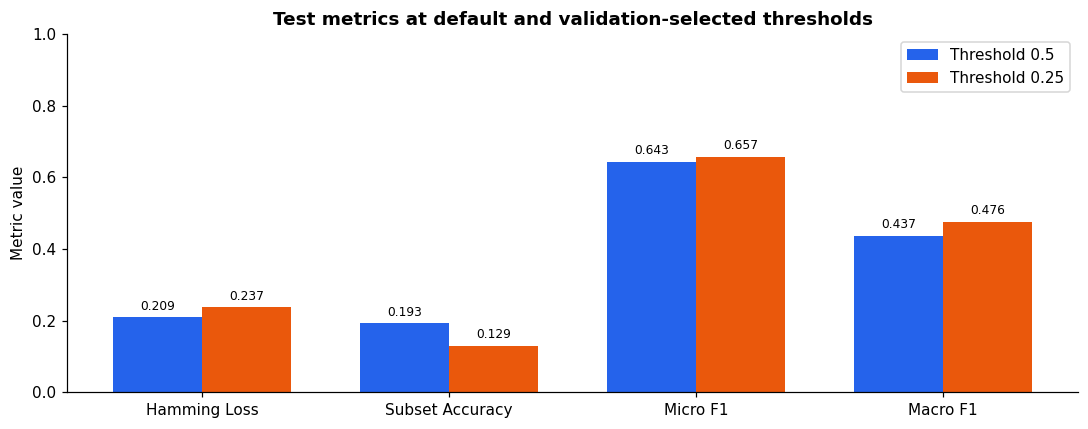

In [13]:
fig, ax=plt.subplots(figsize=(10,4)); x=np.arange(len(comparison_df)); width=.36
for offset,column,color in [(-width/2,comparison_df.columns[1],PALETTE[0]),(width/2,comparison_df.columns[2],PALETTE[2])]:
    bars=ax.bar(x+offset,comparison_df[column],width,label=column,color=color)
    ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=8)
ax.set_xticks(x,comparison_df['Metric']); ax.set(ylabel='Metric value',ylim=(0,1),title='Test metrics at default and validation-selected thresholds')
ax.legend(); plt.tight_layout(); plt.show()

Lower Hamming loss is preferred; higher values are preferred for the other measures. Optimizing validation micro F1 does not necessarily improve every test metric.

## Review questions and interpretation

**Why is Softmax inappropriate?** Softmax forces probabilities across labels to sum to one and models mutually exclusive categories. Independent sigmoid outputs allow any combination of labels. `BCEWithLogitsLoss` combines sigmoid and binary cross entropy in a numerically stable loss, so the model itself returns logits.

**Micro versus macro F1:** micro F1 combines true positives, false positives, and false negatives across all labels before computing F1. Frequent positive labels therefore contribute more. Macro F1 computes F1 for each label and averages equally, making weak performance on rare labels more visible. Both should be reported when labels are imbalanced.

**Hamming loss versus subset accuracy:** Hamming loss is the fraction of individual label decisions that are wrong. Subset accuracy counts a sample as correct only if its complete label vector matches. With many labels, one wrong decision makes the entire sample incorrect, so high subset accuracy is difficult even when many individual labels are correct.

**Threshold tuning:** selecting the threshold on validation data avoids using test labels to choose it. Lower thresholds usually increase positive predictions and recall, potentially reducing precision; higher thresholds reverse that tendency. The tuned threshold maximizes validation micro F1, which need not improve every test metric. Compare the executed table for the actual effect. Ties are resolved using the lowest threshold in the search grid.

**Overfitting:** inspect whether validation loss rises while training loss keeps falling. This notebook reports the final 100-epoch model, rather than silently selecting a checkpoint from the test set.

### Retained run

Validation selected threshold 0.25. On the test set, micro F1 increased from 0.6434 to 0.6572 and macro F1 from 0.4371 to 0.4763. Hamming loss increased from 0.2090 to 0.2373, while subset accuracy fell from 0.1928 to 0.1295. The F1 improvement therefore came with more label errors and fewer exact matches; it does not constitute improvement on every measure.